In [1]:
import pandas as pd

train_path = "../data/train.csv"
test_path = "../data/test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (10003, 2)
Test shape: (3080, 2)


In [4]:
print(train_df.columns)


Index(['text', 'category'], dtype='str')


EDA

In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      10003 non-null  str  
 1   category  10003 non-null  str  
dtypes: str(2)
memory usage: 156.4 KB


In [6]:
print("Missing values:")
print(train_df.isnull().sum())

Missing values:
text        0
category    0
dtype: int64


In [7]:
print("Duplicate rows:", train_df.duplicated().sum())

Duplicate rows: 0


In [8]:
print("Number of categories:", train_df["category"].nunique())

Number of categories: 77


In [9]:
train_df[["text", "category"]].head(10)

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival
5,When did you send me my new card?,card_arrival
6,Do you have info about the card on delivery?,card_arrival
7,What do I do if I still have not received my n...,card_arrival
8,Does the package with my card have tracking?,card_arrival
9,I ordered my card but it still isn't here,card_arrival


EDA chart

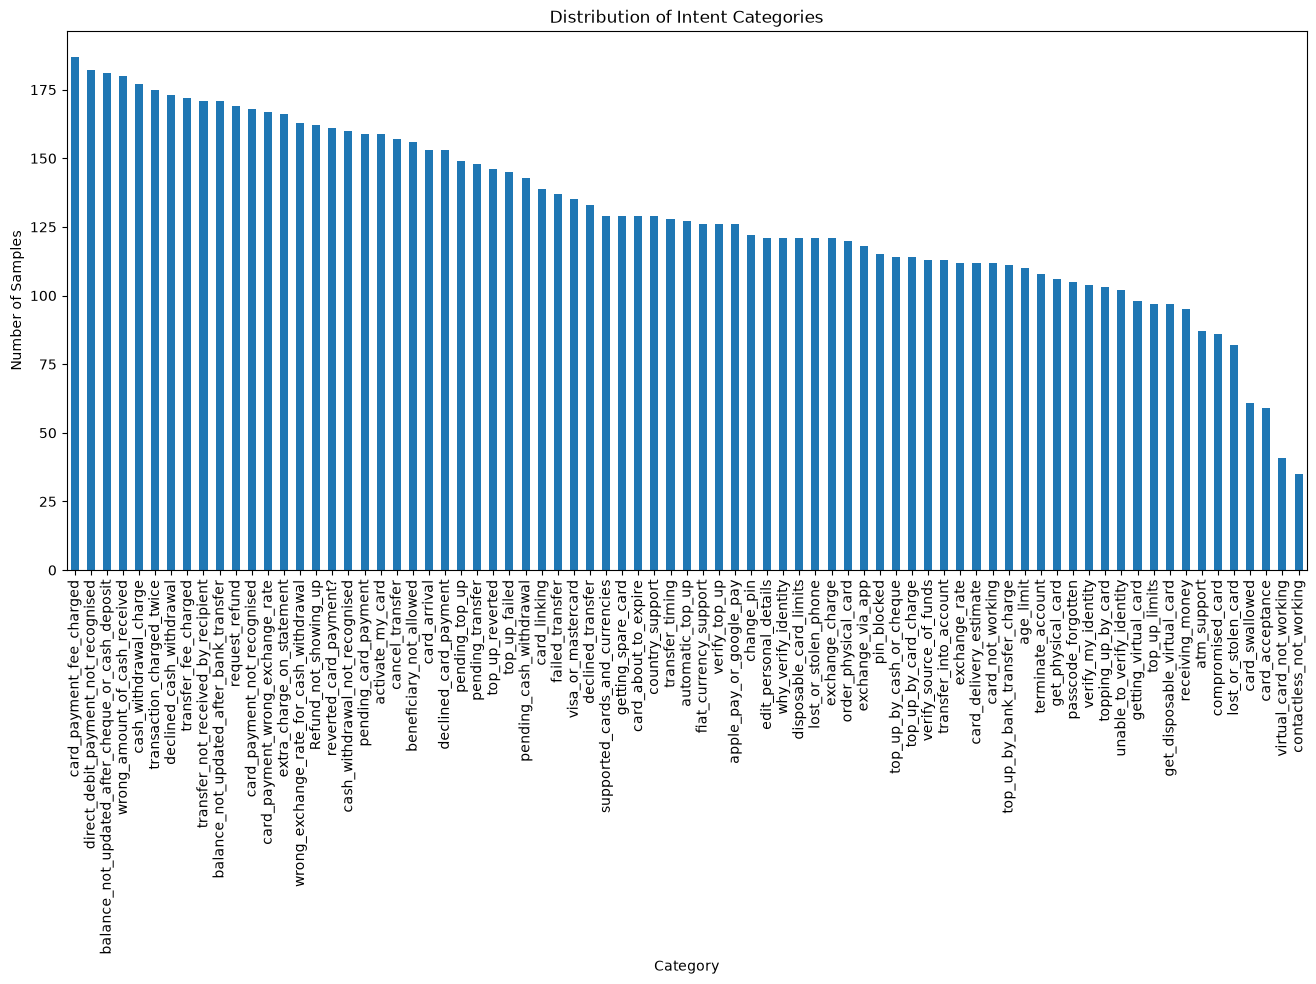

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

train_df["category"].value_counts().plot(kind="bar")

plt.title("Distribution of Intent Categories")
plt.xlabel("Category")
plt.ylabel("Number of Samples")
plt.xticks(rotation=90)

plt.show()

In [13]:
train_df["word_count"] = train_df["text"].str.split().str.len()
train_df["word_count"].describe()

count    10003.000000
mean        11.949415
std          7.891577
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: word_count, dtype: float64

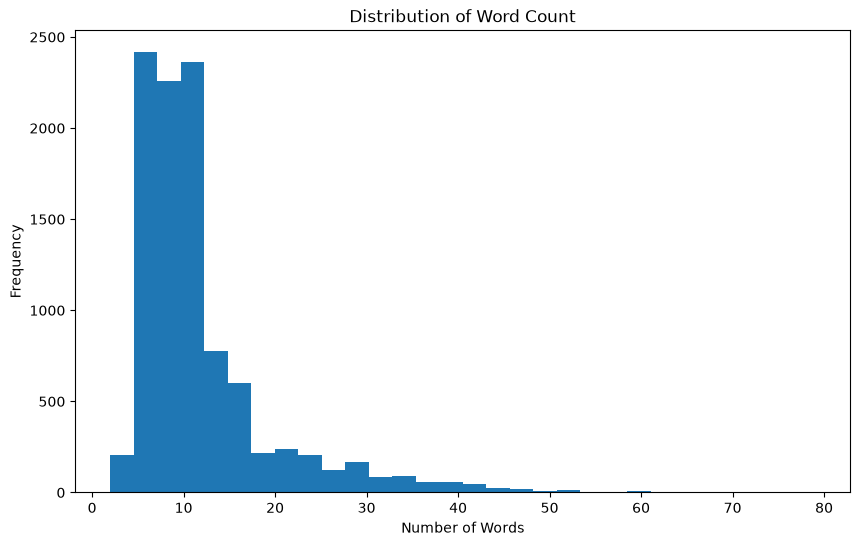

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(train_df["word_count"], bins=30)

plt.title("Distribution of Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [19]:
train_df[["text", "category", "word_count"]].head(10)

,text,category,word_count
0,I am still waiting on my card?,card_arrival,7
1,What can I do if my card still hasn't arrived ...,card_arrival,13
2,I have been waiting over a week. Is the card s...,card_arrival,12
3,Can I track my card while it is in the process...,card_arrival,13
4,"How do I know if I will get my card, or if it ...",card_arrival,15
5,When did you send me my new card?,card_arrival,8
6,Do you have info about the card on delivery?,card_arrival,9
7,What do I do if I still have not received my n...,card_arrival,13
8,Does the package with my card have tracking?,card_arrival,8
9,I ordered my card but it still isn't here,card_arrival,9


In [23]:
category_counts = train_df["category"].value_counts()

print("Number of categories:", len(category_counts))
print("Maximum samples in a category:", category_counts.max())
print("Minimum samples in a category:", category_counts.min())
print("Average samples per category:", category_counts.mean())

Number of categories: 77
Maximum samples in a category: 187
Minimum samples in a category: 35
Average samples per category: 129.9090909090909


In [24]:
print(category_counts.describe())

count     77.000000
mean     129.909091
std       32.942207
min       35.000000
25%      112.000000
50%      127.000000
75%      159.000000
max      187.000000
Name: count, dtype: float64


In [25]:
print("Top 10 categories:")
print(category_counts.head(10))

Top 10 categories:
category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
transaction_charged_twice                           175
declined_cash_withdrawal                            173
transfer_fee_charged                                172
transfer_not_received_by_recipient                  171
balance_not_updated_after_bank_transfer             171
Name: count, dtype: int64


In [26]:
train_df[["text", "category"]].sample(10, random_state=42)

,text,category
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer
5573,Why am I getting declines when trying to make ...,declined_transfer
576,What is the $1 transaction on my account?,extra_charge_on_statement
6832,It looks like my card payment was sent back.,reverted_card_payment?
7111,Why am I unable to transfer money when I was a...,beneficiary_not_allowed
439,What if there is an error on the exchange rate?,card_payment_wrong_exchange_rate


Clean EDA summary

In [29]:
# Check columns first
print("Columns:", train_df.columns.tolist())

# Create required EDA columns
train_df["text_length"] = train_df["text"].astype(str).str.len()
train_df["word_count"] = train_df["text"].astype(str).str.split().str.len()

# Category analysis
category_counts = train_df["category"].value_counts()

print("\nNumber of categories:", train_df["category"].nunique())
print("Missing values:", train_df.isnull().sum().sum())
print("Duplicate rows:", train_df.duplicated().sum())

print("\nTop 10 categories:")
print(category_counts.head(10))

print("\nBottom 10 categories:")
print(category_counts.tail(10))

print("\nText length:")
print(train_df["text_length"].describe())

print("\nWord count:")
print(train_df["word_count"].describe())

Columns: ['text', 'category', 'word_count']

Number of categories: 77
Missing values: 0
Duplicate rows: 0

Top 10 categories:
category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
transaction_charged_twice                           175
declined_cash_withdrawal                            173
transfer_fee_charged                                172
transfer_not_received_by_recipient                  171
balance_not_updated_after_bank_transfer             171
Name: count, dtype: int64

Bottom 10 categories:
category
top_up_limits                  97
get_disposable_virtual_card    97
receiving_money                95
atm_support                    87
compromised_card               86
lost_or_stolen_card            82
card_swallowed                 61
card_acce

## EDA Observations

- The dataset contains 10,003 training samples.
- The test dataset contains 3,080 samples.
- The dataset contains 77 intent categories.
- Text length and word count vary across user queries.
- Category distribution was analyzed to identify class imbalance.
- Missing values and duplicate records were checked.